# 36. 두 전문가 앙상블(A) + 변수 간 관계 이탈(B)

**왜**: ① CN7 AP 0.373 ≈ 미성형 6행 몫(0.353) + 가스 약간 → 더 올리려면 **가스**를 잡아야 함 (이론 상한 ≈ 0.80)

| 방법 | 내용 |
|---|---|
| A_gas_expert | 가스 전문가 단독 — CN7: 온도 교란 점수 E(29번, 재가동 15샷 제외) / RG3: 흔들림 std4 Mahalanobis |
| A_max | max(최종 pct, 가스 pct) → reference로 다시 백분위 보정 |
| B_rel_maha / B_rel_max | 원값 21개를 '같은 샷의 나머지 + 자기 과거'로 예측한 잔차 → Mahalanobis / 최대 |z| |
| B_max, AB_max | 최종 + B / 최종 + 가스 + B 를 max로 |

- 모두 공정 데이터만, 라벨 미사용, 결과 보기 전 고정
- ⚠ CN7 E 규칙은 R1을 보고 방향을 정함 → CN7 개선분은 사후 확인 성격
- 핵심 확인 열: **`① 상위k% 가스행`** (가스가 순위 위로 올라왔는가), `ΔAP 95%CI`

In [1]:
import pandas as pd
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 250)
from plot_style import set_style; set_style()
import ensemble_relation as E
R = E.run(('cn7', 'rg3'))

[cn7] reference 5,179샷 (관계모델 학습 1,465 / 검증 3,714) | labeled 1,979샷
  [cn7] 완료
[rg3] reference 4,359샷 (관계모델 학습 2,281 / 검증 2,078) | labeled 629샷
  [rg3] 완료


## 1. 한눈 표

In [2]:
cols = ['제품', '모델', '① AP', '① 상위1% 미성형행', '① 상위1% 가스행', '① 상위5% 미성형행', '① 상위5% 가스행',
        '① 상위10% 미성형행', '① 상위10% 가스행', '② AP', '② AP 95%CI', '② AP_가스', '② AP_미성형',
        'Run별 상위10% 가스', 'Run별 상위10% 미성형', 'ΔAP(②, vs 최종)', 'ΔAP 95%CI', 'P(최종보다 좋음)', '유의하게 좋음']
for p in ('cn7', 'rg3'):
    print(f'===== {p.upper()} =====')
    display(R['summary'].query('제품 == @p')[cols].round(3))

===== CN7 =====


,제품,모델,① AP,① 상위1% 미성형행,① 상위1% 가스행,① 상위5% 미성형행,① 상위5% 가스행,① 상위10% 미성형행,① 상위10% 가스행,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10% 가스,Run별 상위10% 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음
0,cn7,final (최종),0.373,4/4,2/13,4/4,2/13,4/4,4/13,0.212,"[0.011, 0.416]",0.007,0.751,1/11,3/4,NaN,NaN,NaN,NaN
1,cn7,A_gas_expert,0.417,3/4,3/13,4/4,7/13,4/4,8/13,0.259,"[0.088, 0.524]",0.113,0.462,6/11,3/4,0.047,"[-0.094, +0.247]",0.763,-
2,cn7,"A_max(final,gas)",0.417,4/4,2/13,4/4,4/13,4/4,8/13,0.165,"[0.033, 0.408]",0.026,0.480,3/11,3/4,-0.024,"[-0.086, +0.054]",0.433,-
3,cn7,B_rel_maha,0.364,4/4,2/13,4/4,2/13,4/4,2/13,0.132,"[0.005, 0.338]",0.003,0.480,4/11,3/4,-0.079,"[-0.146, -0.002]",0.000,-
4,cn7,B_rel_max,0.009,0/4,0/13,0/4,0/13,0/4,0/13,0.005,"[0.004, 0.007]",0.003,0.003,1/11,3/4,-0.207,"[-0.412, -0.006]",0.000,-
5,cn7,"B_max(final,B)",0.364,4/4,2/13,4/4,2/13,4/4,2/13,0.132,"[0.005, 0.338]",0.003,0.480,2/11,3/4,-0.057,"[-0.120, -0.002]",0.000,-
6,cn7,"AB_max(final,gas,B)",0.366,4/4,2/13,4/4,2/13,4/4,2/13,0.132,"[0.005, 0.338]",0.004,0.480,3/11,3/4,-0.057,"[-0.120, -0.002]",0.000,-


===== RG3 =====


,제품,모델,① AP,① 상위1% 미성형행,① 상위1% 가스행,① 상위5% 미성형행,① 상위5% 가스행,① 상위10% 미성형행,① 상위10% 가스행,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10% 가스,Run별 상위10% 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음
7,rg3,final (최종),0.024,0/8,0/17,0/8,1/17,1/8,1/17,0.064,"[0.051, 0.101]",0.050,0.021,2/22,1/10,NaN,NaN,NaN,NaN
8,rg3,A_gas_expert,0.030,0/8,1/17,1/8,1/17,1/8,1/17,0.072,"[0.054, 0.125]",0.051,0.031,1/22,1/10,0.008,"[-0.020, +0.047]",0.748,-
9,rg3,"A_max(final,gas)",0.026,0/8,1/17,1/8,1/17,1/8,1/17,0.064,"[0.049, 0.110]",0.046,0.026,1/22,1/10,0.001,"[-0.023, +0.029]",0.507,-
10,rg3,B_rel_maha,0.023,0/8,0/17,0/8,1/17,0/8,3/17,0.081,"[0.055, 0.139]",0.071,0.021,4/22,0/10,0.018,"[-0.015, +0.067]",0.857,-
11,rg3,B_rel_max,0.022,0/8,0/17,0/8,2/17,0/8,2/17,0.090,"[0.043, 0.174]",0.096,0.016,3/22,0/10,0.003,"[-0.032, +0.073]",0.583,-
12,rg3,"B_max(final,B)",0.022,0/8,0/17,0/8,1/17,0/8,2/17,0.075,"[0.053, 0.124]",0.064,0.021,3/22,1/10,0.011,"[-0.019, +0.047]",0.752,-
13,rg3,"AB_max(final,gas,B)",0.024,0/8,0/17,1/8,1/17,1/8,2/17,0.076,"[0.052, 0.131]",0.063,0.022,2/22,1/10,0.011,"[-0.015, +0.047]",0.765,-


## 2. 경보 (정상 오경보율 가정 1% / 0.1%) — 경보 비율이 q와 맞는지(보정)도 확인

In [3]:
c2 = ['제품', '모델', 'q0.99 경보', 'q0.99 경보 비율', 'q0.99 가스', 'q0.99 미성형', 'q0.999 경보', 'q0.999 TP', 'q0.999 가스', 'q0.999 미성형']
display(R['summary'][c2].round(3))

,제품,모델,q0.99 경보,q0.99 경보 비율,q0.99 가스,q0.99 미성형,q0.999 경보,q0.999 TP,q0.999 가스,q0.999 미성형
0,cn7,final (최종),29,0.015,0,3,8,3,0,3
1,cn7,A_gas_expert,1,0.001,0,1,0,0,0,0
2,cn7,"A_max(final,gas)",23,0.012,0,3,7,3,0,3
3,cn7,B_rel_maha,1142,0.579,0,3,12,3,0,3
4,cn7,B_rel_max,1786,0.905,0,1,1786,1,0,1
5,cn7,"B_max(final,B)",990,0.502,0,3,12,3,0,3
6,cn7,"AB_max(final,gas,B)",584,0.296,0,3,10,3,0,3
7,rg3,final (최종),9,0.014,0,0,3,0,0,0
8,rg3,A_gas_expert,20,0.032,1,1,6,0,0,0
9,rg3,"A_max(final,gas)",15,0.024,1,0,5,0,0,0


## 3. CN7 가스 집중 Run — 전문가별 점수

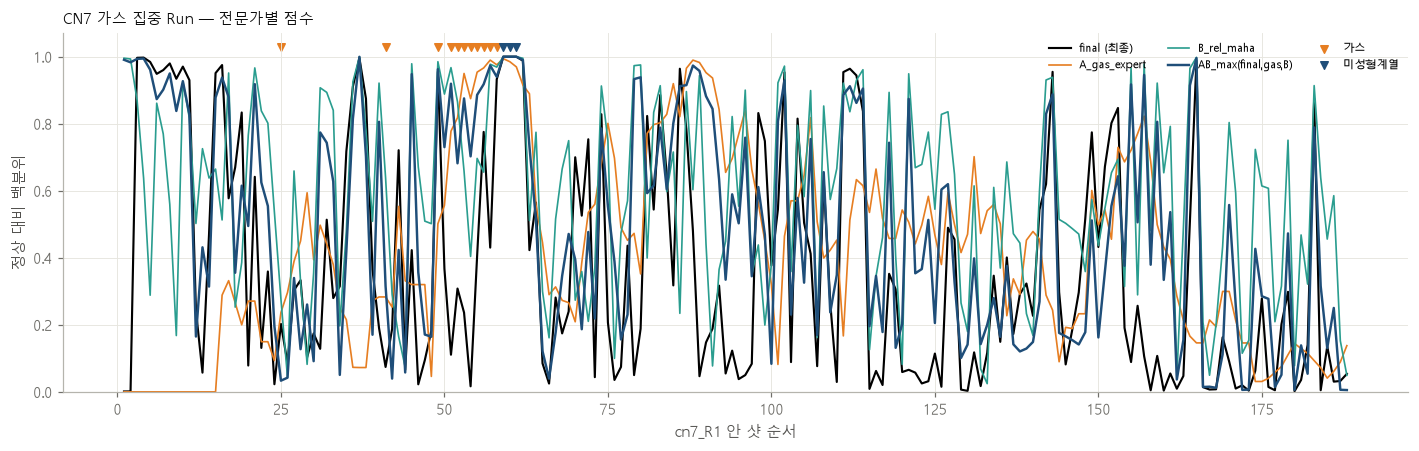

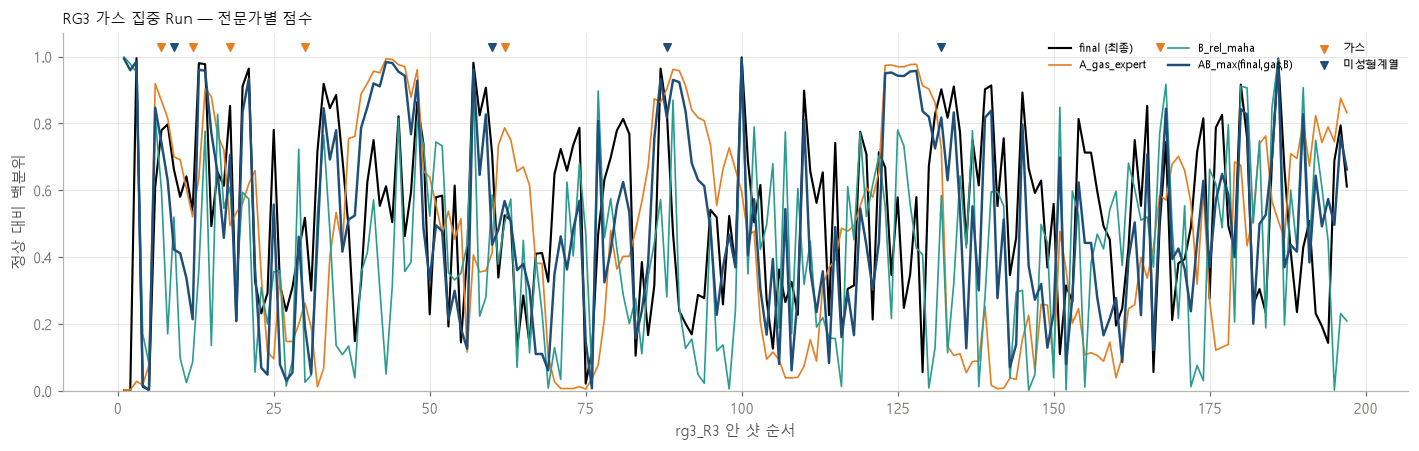

In [4]:
E.plot_run(R, 'cn7', save='./outputs/ensemble_relation/cn7_run.png')
E.plot_run(R, 'rg3', save='./outputs/ensemble_relation/rg3_run.png')

## 4. B 관계 이탈 — 불량 샷에서 잔차가 가장 컸던 변수 (설명용)

In [5]:
for p in ('cn7', 'rg3'):
    d = R['scores'][p]
    d = d[d['eval'] & (d['PassOrFail'] == 1)]
    print(f'===== {p.upper()} 불량 샷 =====')
    display(d.groupby('Reason')['B_최대잔차변수'].value_counts().rename('샷 수').reset_index())

===== CN7 불량 샷 =====


,Reason,B_최대잔차변수,샷 수
0,가스,Barrel_Temperature_4,3
1,가스,Max_Screw_RPM,2
2,가스,Barrel_Temperature_6,2
3,가스,Barrel_Temperature_3,2
4,가스,Barrel_Temperature_5,1
5,가스,Cycle_Time,1
6,가스+미성형,Max_Injection_Speed,2
7,미성형,Max_Injection_Speed,1
8,미성형,Cycle_Time,1


===== RG3 불량 샷 =====


,Reason,B_최대잔차변수,샷 수
0,가스,Mold_Temperature_4,8
1,가스,Plasticizing_Time,5
2,가스,Max_Switch_Over_Pressure,3
3,가스,Mold_Temperature_3,1
4,가스,Barrel_Temperature_4,1
5,가스,Barrel_Temperature_2,1
6,가스,Hopper_Temperature,1
7,가스,Cushion_Position,1
8,가스,Cycle_Time,1
9,미성형,Mold_Temperature_4,4
